# Mapping stability across the parameter surface

The selection frequency of a candidate setting across repeated histories is:

$$
\widehat\pi(\theta)=\frac{1}{M}\sum_{m=1}^{M}\mathbf 1\{\widehat\theta_m=\theta\}.
$$

Here, $M$ is the number of expanding histories, $m$ identifies one history, $\widehat\theta_m$ is its selected setting, $\mathbf 1\{\cdot\}$ is the indicator function, and $\widehat\pi(\theta)$ is the observed selection share of setting $\theta$.

In [1]:
include(joinpath("..","support","BookFeatureMath.jl"))
using RiskLabAI, Random, Statistics, LinearAlgebra, DataFrames, Dates, Plots
include(joinpath("..", "support", "BookSupport.jl"))
using .BookSupport
import .BookSupport: palette
@assert pkgversion(RiskLabAI) == v"1.1.0"
configure_plots!()
paths = output_paths("18_hyperparameter_selection");
using CSV, TOML, Printf
include(joinpath("..","support","BookEstimators.jl"))
include(joinpath("..","support","BookSVC.jl"))
using RiskLabAI.Validation: KFoldCV,PurgedKFoldCV,cv_split,filtered_training_indices_with_embargo,SampleWeightedPipeline,clf_hyper_fit,predict_pipeline,predict_pipeline_proba
prefix = "stability"
raw = load_binance()
raw.interval = floor.(raw.time,Minute(15))

function compensated_sum(values)
    total,correction = 0.,0.
    for value in values
        adjusted = value-correction
        updated = total+adjusted
        correction = updated-total-adjusted
        total = updated
    end
    return total
end

bars = combine(groupby(raw,:interval;sort=true),:close=>last=>:Close,:volume=>compensated_sum=>:Volume,:quote_volume=>compensated_sum=>Symbol("Quote volume"),:trades=>compensated_sum=>:Trades)
function rolling_standard_deviation(values,window)
    result = fill(NaN,length(values))
    count,center,squares,add_correction,remove_correction = 0,0.,0.,0.,0.
    for index in eachindex(values)
        if index>window && isfinite(values[index-window])
            value = values[index-window]
            count -= 1
            if count>0
                previous = center-remove_correction
                adjusted = value-remove_correction
                difference = adjusted-center
                remove_correction = difference+center-adjusted
                center -= difference/count
                squares -= (value-previous)*(value-center)
            else
                center,squares = 0.,0.
            end
        end
        value = values[index]
        if isfinite(value)
            count += 1
            previous = center-add_correction
            adjusted = value-add_correction
            difference = adjusted-center
            add_correction = difference+center-adjusted
            center += difference/count
            squares += (value-previous)*(value-center)
        end
        count==window && (result[index]=sqrt(max(0.,squares/(count-1))))
    end
    return result
end

function exponential_average(values,span)
    alpha = 2/(span+1)
    result = copy(values)
    for index in 2:length(values)
        result[index] = (1-alpha)*result[index-1]+alpha*values[index]
    end
    return result
end

levels = BookFeatureMath.runtime_log.(bars.Close)
returns = vcat(NaN,diff(levels))
positions = collect(18:nrow(bars)-8)
feature_names = ["Previous return","Distance from EWM 15","Distance from EWM 55","One-hour return","Past volatility","Log volume change"]
public_x = hcat(returns[positions.-1],(levels.-BookFeatureMath.runtime_log.(exponential_average(bars.Close,15)))[positions.-1],(levels.-BookFeatureMath.runtime_log.(exponential_average(bars.Close,55)))[positions.-1],levels[positions.-1].-levels[positions.-5],rolling_standard_deviation(returns,16)[positions.-1],diff(BookFeatureMath.runtime_log1p.(bars.Volume))[positions.-2])
dates,event_times = bars.interval[positions],bars.interval[positions.+8]
forward_returns = levels[positions.+8].-levels[positions]
public_y = Int.(forward_returns.>0)
sample_weight = clamp.(abs.(forward_returns)./median(abs.(forward_returns)),.25,4.)
count_observations = length(public_y)
feature_frame = DataFrame(position=collect(1:count_observations),bar_position=positions,date=dates,end_time=event_times,forward_return=forward_returns,target=public_y,weight=sample_weight)
for (column,name) in enumerate(feature_names)
    feature_frame[!,name] = public_x[:,column]
end
save_data(feature_frame,paths,prefix*"_features")
save_data(bars,paths,prefix*"_bars")
@assert nrow(bars)==2976 && size(public_x)==(2951,6)
@assert all(isfinite,public_x) && all(value->.25<=value<=4.,sample_weight)
violet = "#C084FC"
format_time(value) = Dates.format(value,dateformat"yyyy-mm-dd HH:MM:SS")
configuration_name(kernel,penalty) = uppercase(string(kernel))*", C="*@sprintf("%g",penalty)
configurations(penalties) = [(kernel,Float64(penalty)) for kernel in ["linear","rbf"] for penalty in penalties]
selected_row(frame) = first(eachrow(sort(frame,["Mean F1","Order"];rev=[true,false])))
table(frame,name,caption) = save_table(frame,paths,name;caption,label="tab:chapter18-"*replace(name,"_"=>"-"))
fit_cache = Dict{Tuple,Any}()
fit_records,prediction_records = NamedTuple[],NamedTuple[]

function f1_value(actual,predicted;weights=ones(length(actual)))
    true_positive = sum(weights[(actual.==1).&(predicted.==1)])
    false_positive = sum(weights[(actual.==0).&(predicted.==1)])
    false_negative = sum(weights[(actual.==1).&(predicted.==0)])
    denominator = 2true_positive+false_positive+false_negative
    return denominator==0 ? 0. : 2true_positive/denominator
end

function record_fit(model,kernel,penalty,train,weights;source="manual")
    number = length(fit_records)+1
    push!(fit_records,(fit=number,source=source,kernel=string(kernel),C=Float64(penalty),observations=length(train),weight_sum=sum(weights),support_vectors=count(>(0),model.alpha),intercept=model.intercept,gamma=model.gamma,iterations=model.iterations,converged=model.converged,kkt_violation=model.kkt_violation,dual_objective=model.dual_objective,primal_objective=model.primal_objective))
    save_data(DataFrame(position=train,weight=weights),paths,prefix*"_fit_"*string(number)*"_weights")
    save_data(DataFrame(fit_records),paths,prefix*"_fits")
    @assert model.converged
    return number
end

function fitted_for(kernel,penalty,train;weights=sample_weight[train])
    key = (string(kernel),Float64(penalty),Tuple(train),Tuple(weights))
    return get!(fit_cache,key) do
        model = BookSVC.fit_svc(public_x[train,:],public_y[train];sample_weight=weights,C=penalty,kernel=Symbol(kernel))
        number = record_fit(model,kernel,penalty,train,weights)
        return model,number
    end
end

function record_predictions(model,number,test,key)
    scores = BookEstimators.decision_function(model,public_x[test,:])
    predictions = BookEstimators.predict(model,public_x[test,:])
    for (position,prediction,score) in zip(test,predictions,scores)
        push!(prediction_records,(case=key,fit=number,position=position,prediction=prediction,score=score))
    end
    return predictions
end

function evaluate(kernel,penalty,train,test,key)
    model,number = fitted_for(kernel,penalty,train)
    return f1_value(public_y[test],record_predictions(model,number,test,key))
end

function save_predictions()
    isempty(prediction_records) || save_data(DataFrame(prediction_records),paths,prefix*"_predictions")
    return nothing
end

function configuration_surface(configs;rows=collect(1:count_observations),folds=5,embargo=.01,ordinary=false,key)
    local_splits = ordinary ? cv_split(KFoldCV(folds),length(rows)) : cv_split(PurgedKFoldCV(folds,dates[rows],event_times[rows];embargo))
    splits = [(rows[train],rows[test]) for (train,test) in local_splits]
    memberships = DataFrame(fold=Int[],role=String[],order=Int[],position=Int[])
    for (fold,(train,test)) in enumerate(splits), (role,indices) in [("train",train),("test",test)]
        append!(memberships,DataFrame(fold=fill(fold,length(indices)),role=fill(role,length(indices)),order=collect(eachindex(indices)),position=indices))
    end
    save_data(memberships,paths,key*"_splits")
    records = NamedTuple[]
    for (order,(kernel,penalty)) in enumerate(configs)
        scores = [evaluate(kernel,penalty,train,test,key*"_"*string(order)*"_"*string(fold)) for (fold,(train,test)) in enumerate(splits)]
        push!(records,(order=order-1,configuration=configuration_name(kernel,penalty),kernel=kernel,penalty=penalty,mean=mean(scores),spread=std(scores),minimum=minimum(scores),maximum=maximum(scores),training=mean(length(train) for (train,_) in splits),removed=mean(length(rows)-length(train)-length(test) for (train,test) in splits)))
    end
    result = DataFrame(records)
    rename!(result,["Order","Configuration","Kernel","C","Mean F1","F1 spread","Smallest fold F1","Largest fold F1","Mean training observations","Mean removed observations"])
    ordinary && (result=select(result,1:8))
    save_data(result,paths,key*"_surface")
    save_predictions()
    return result,splits
end

function overlap_count(train,test)
    allowed = Set(filtered_training_indices_with_embargo(dates,event_times,test;embargo=0.,continuous=true))
    return count(index->index∉allowed,train)
end

function selection_frequency(frame,count_name)
    result = combine(groupby(frame,["Selected kernel","Selected C"];sort=true),nrow=>count_name)
    result[!,"Selection share"] = result[!,count_name]./nrow(frame)
    return result
end

function read_primitive(name)
    root = joinpath("..","data","chapter18_random_inputs")
    manifest_path = joinpath(root,"inputs.toml")
    entry = TOML.parsefile(manifest_path)["files"][name]
    path = joinpath(root,name)
    return CSV.read(path,DataFrame)
end

function native_pipeline(source)
    row_lookup = Dict(Tuple(row)=>index for (index,row) in enumerate(eachrow(public_x)))
    current_train,current_scaler = Ref(Int[]),Ref(BookSVC.fit_scaler(public_x))
    fit_step = function(name,step,data,labels,options)
        if name=="scale"
            current_train[] = [row_lookup[Tuple(row)] for row in eachrow(data)]
            current_scaler[] = BookSVC.fit_scaler(data)
            return current_scaler[]
        end
        weights = get(options,"sample_weight",ones(length(labels)))
        model = BookSVC.fit_svc(data,labels;sample_weight=weights,C=step.C,kernel=Symbol(step.kernel),standardize=false)
        number = record_fit(model,step.kernel,step.C,current_train[],weights;source)
        transformed = BookEstimators.transform(current_scaler[],public_x)
        lookup = Dict(Tuple(row)=>index for (index,row) in enumerate(eachrow(transformed)))
        return (;model,number,lookup,kernel=step.kernel,C=step.C)
    end
    predict_step = function(name,fitted,data)
        predicted = BookEstimators.predict(fitted.model,data)
        scores = BookEstimators.decision_function(fitted.model,data)
        positions = [fitted.lookup[Tuple(row)] for row in eachrow(data)]
        for (position,prediction,score) in zip(positions,predicted,scores)
            push!(prediction_records,(case=source,fit=fitted.number,position=position,prediction=prediction,score=score))
        end
        return predicted
    end
    return SampleWeightedPipeline(["scale"=>:scale,"svc"=>(;kernel="rbf",C=1.)];clone_step=(name,step,args...)->name=="scale" ? :scale : (;kernel=step.kernel,C=step.C),fit_step,transform_step=(name,scaler,data)->BookEstimators.transform(scaler,data),predict_step,classes_step=(name,fitted)->fitted.model.classes,configure_step=(name,step,options)->name=="svc" ? (;kernel=get(options,"kernel",step.kernel),C=Float64(get(options,"C",step.C))) : step)
end

function released_search(grid,key;weights=nothing,random_candidates=nothing,bagging=nothing)
    options = Dict{Symbol,Any}(:sample_weight=>weights,:return_search=>true,:error_score=>:raise)
    if random_candidates!==nothing
        options[:rnd_search_iter] = length(random_candidates)
        options[:candidate_indices] = random_candidates
    end
    if bagging!==nothing
        options[:bagging] = bagging
        options[:bagging_sample_indices] = [read_primitive("bag_member_"*string(index)*".csv").position for index in 1:5]
        options[:bagging_feature_indices] = [collect(1:6) for _ in 1:5]
        options[:bagging_estimator_seeds] = read_primitive("member_seeds.csv").seed
    end
    result = clf_hyper_fit(PurgedKFoldCV(5,dates,event_times;embargo=.01),public_x,public_y,native_pipeline(key),grid;options...)
    rows = NamedTuple[]
    for (candidate,parameters) in enumerate(result.candidates), fold in axes(result.fold_scores,2)
        push!(rows,(candidate=candidate,fold=fold,kernel=parameters["svc__kernel"],C=parameters["svc__C"],score=result.fold_scores[candidate,fold],mean_score=result.mean_scores[candidate],selected=candidate==result.best_index))
    end
    save_data(DataFrame(rows),paths,key*"_scores")
    predictions = predict_pipeline(result.estimator,public_x)
    save_data(DataFrame(position=collect(1:count_observations),prediction=predictions),paths,key*"_predictions")
    save_predictions()
    return result
end


released_search (generic function with 1 method)

## Expanding-History Selections

Row,Window,Observations,History ends,Selected kernel,Selected C,Best mean F1,Second mean F1,Score margin
,Int64,Int64,String,String,Float64,Float64,Float64,Float64
1,1,900,2021-01-10 13:00:00,linear,0.01,0.724676,0.724676,0.0
2,2,1200,2021-01-13 16:00:00,rbf,0.01,0.697182,0.555224,0.141959
3,3,1500,2021-01-16 19:00:00,linear,0.01,0.691662,0.691662,0.0
4,4,1800,2021-01-19 22:00:00,rbf,0.01,0.690645,0.633695,0.0569506
5,5,2100,2021-01-23 01:00:00,rbf,10.0,0.523597,0.513665,0.00993272
6,6,2400,2021-01-26 04:00:00,rbf,10.0,0.496329,0.492691,0.00363866
7,7,2951,2021-01-31 21:45:00,rbf,10.0,0.518038,0.498818,0.0192207


Row,Window,Observations,Configuration,Kernel,C,Mean F1,F1 spread
,Int64,Int64,String,String,Float64,Float64,Float64
1,1,900,"LINEAR, C=0.01",linear,0.01,0.724676,0.0490689
2,1,900,"LINEAR, C=0.1",linear,0.1,0.724676,0.0490689
3,1,900,"LINEAR, C=1",linear,1.0,0.724676,0.0490689
4,1,900,"LINEAR, C=10",linear,10.0,0.724676,0.0490689
5,1,900,"RBF, C=0.01",rbf,0.01,0.724676,0.0490689
6,1,900,"RBF, C=0.1",rbf,0.1,0.705294,0.0623103
7,1,900,"RBF, C=1",rbf,1.0,0.596173,0.130682
8,1,900,"RBF, C=10",rbf,10.0,0.540607,0.100195
9,2,1200,"LINEAR, C=0.01",linear,0.01,0.548148,0.249871


Row,Selected kernel,Selected C,Selections,Selection share
,String,Float64,Int64,Float64
1,linear,0.01,2,0.285714
2,rbf,0.01,2,0.285714
3,rbf,10.0,3,0.428571


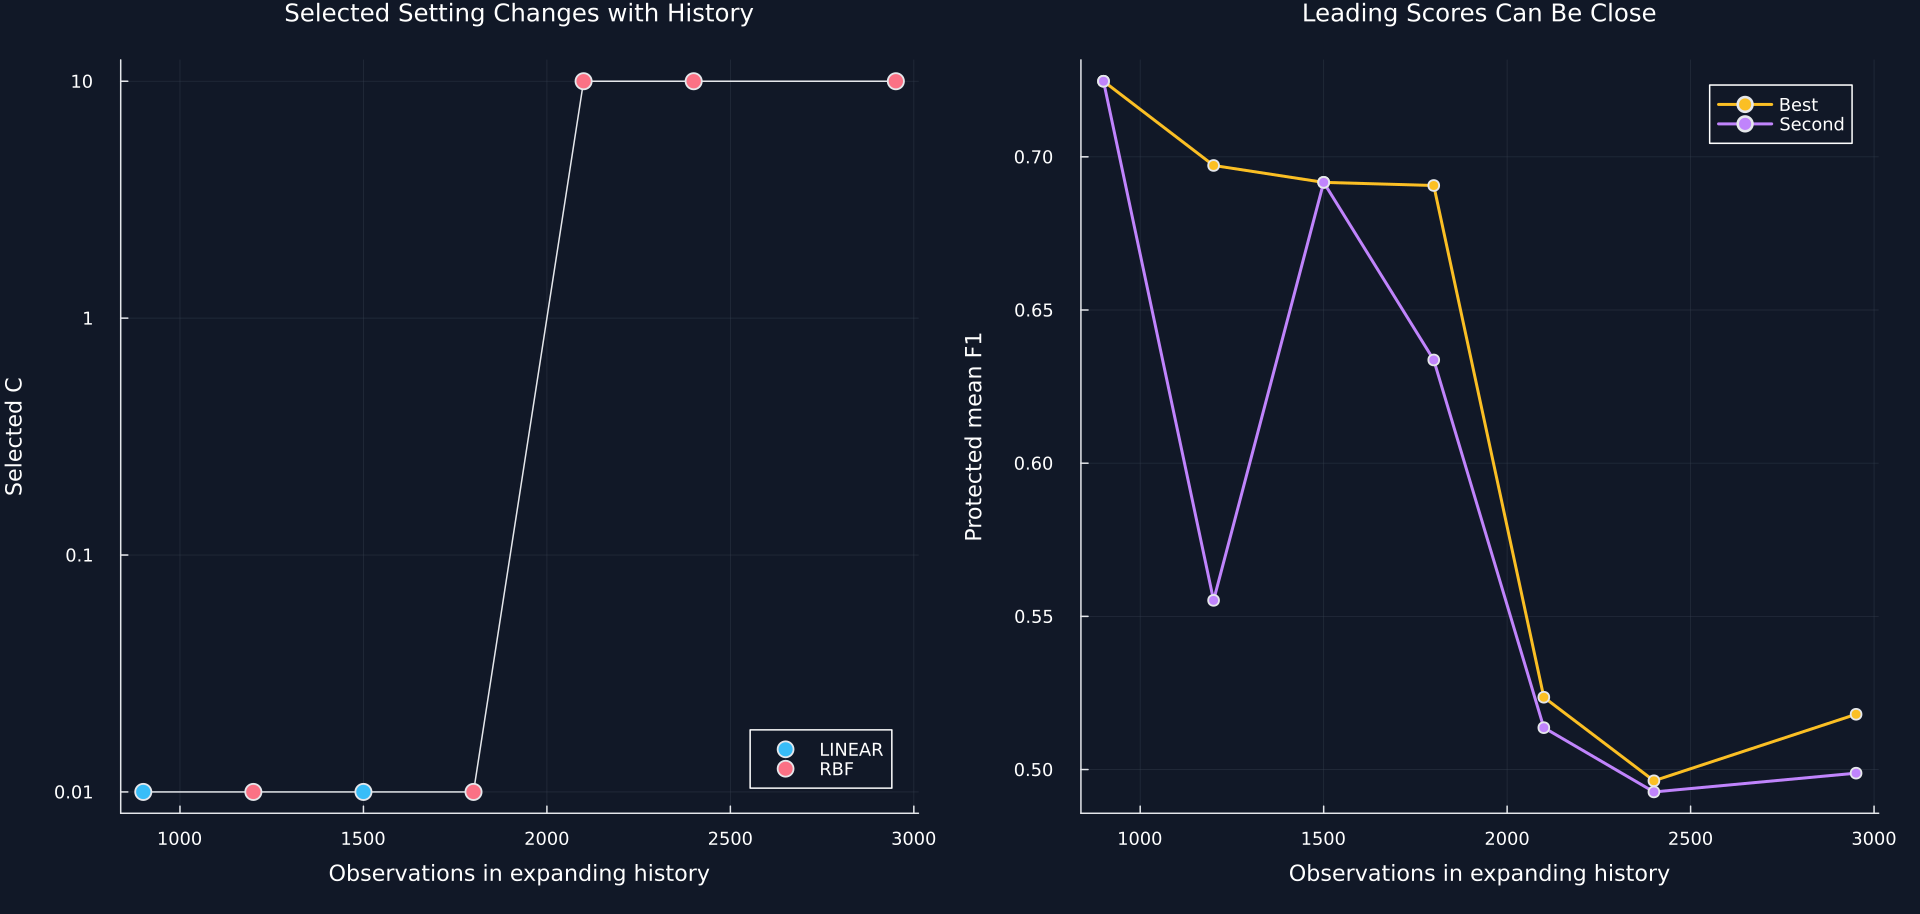

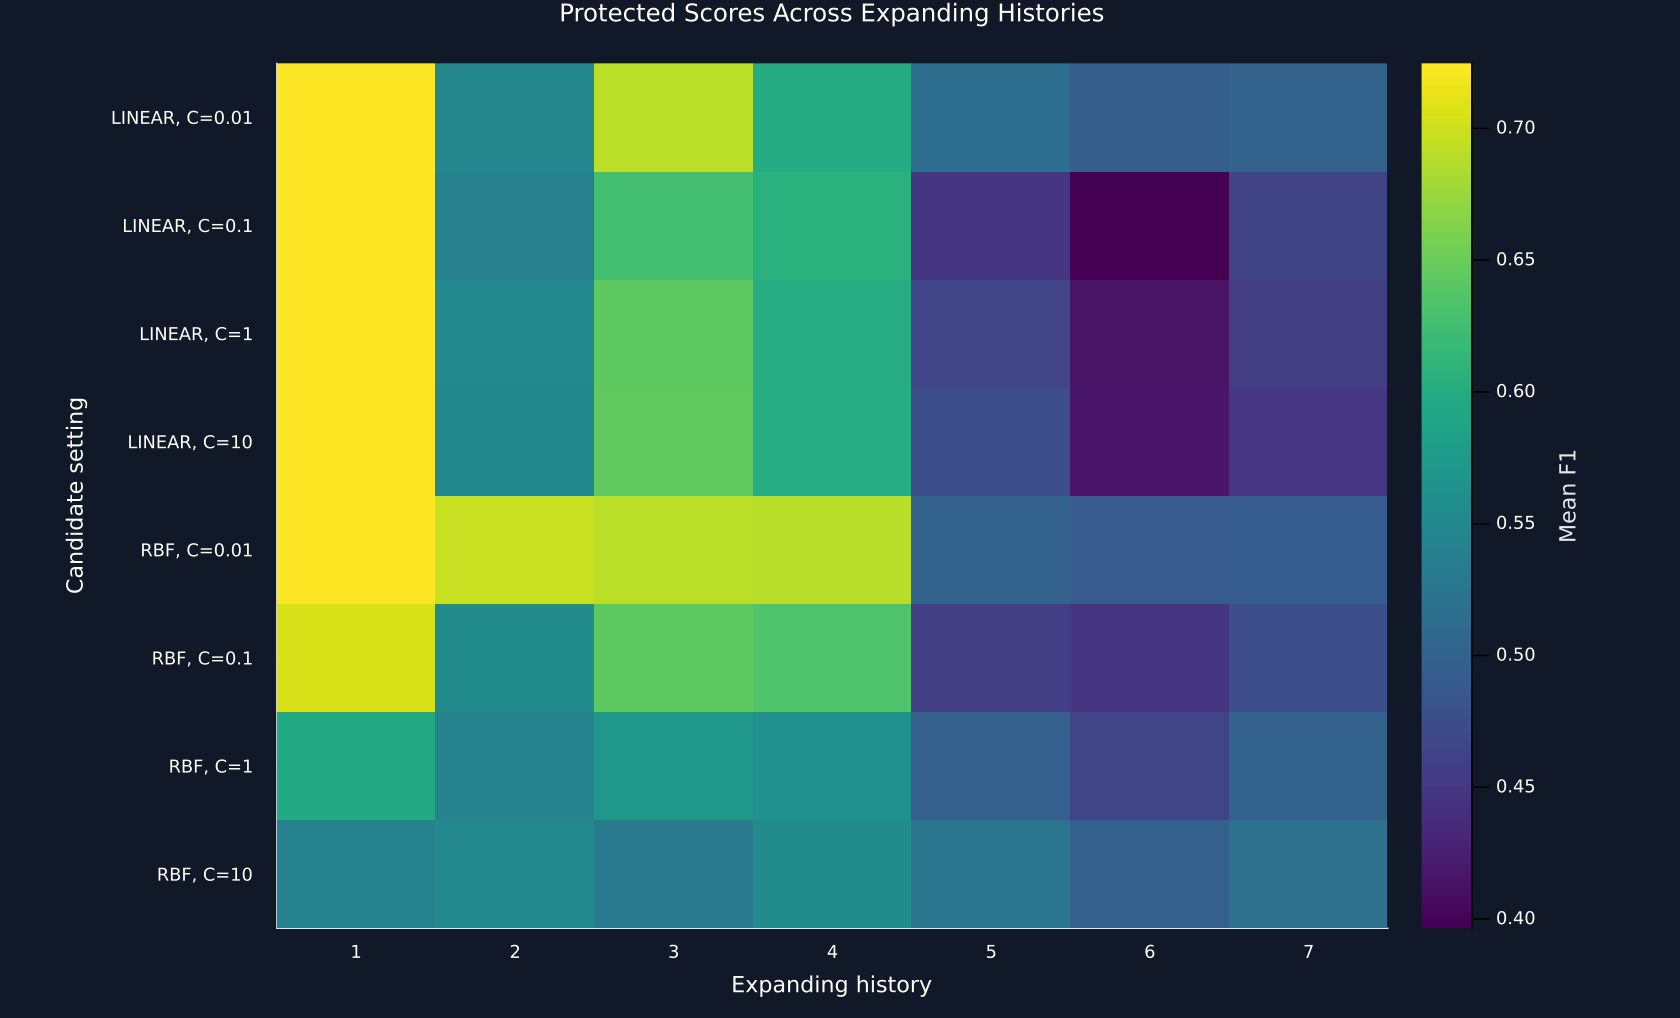

In [2]:
stability_configurations = configurations([.01,.1,1.,10.])
history_sizes = [900,1200,1500,1800,2100,2400,count_observations]
history_records,history_surfaces = NamedTuple[],DataFrame[]
for (window,history_size) in enumerate(history_sizes)
    surface,_ = configuration_surface(stability_configurations;rows=collect(1:history_size),folds=4,key="history_"*string(window))
    ordered = sort(surface,["Mean F1","Order"];rev=[true,false])
    best,second = ordered[1,:],ordered[2,:]
    push!(history_records,(window=window,observations=history_size,ends=format_time(dates[history_size]),kernel=best.Kernel,C=best.C,best=best["Mean F1"],second=second["Mean F1"],margin=best["Mean F1"]-second["Mean F1"]))
    current = select(surface,["Configuration","Kernel","C","Mean F1","F1 spread"])
    insertcols!(current,1,"Window"=>fill(window,nrow(current)),"Observations"=>fill(history_size,nrow(current)))
    push!(history_surfaces,current)
end
expanding_history_selections = DataFrame(history_records)
rename!(expanding_history_selections,["Window","Observations","History ends","Selected kernel","Selected C","Best mean F1","Second mean F1","Score margin"])
expanding_history_surface = vcat(history_surfaces...)
expanding_selection_frequency = selection_frequency(expanding_history_selections,"Selections")
table(expanding_history_selections,"expanding_history_selections","Selected settings across seven expanding public-data histories.")
table(expanding_history_surface,"expanding_history_surface","Complete protected score surfaces across seven expanding histories.")
table(expanding_selection_frequency,"expanding_selection_frequency","Selection frequencies across the expanding histories.")
p1 = plot(history_sizes,expanding_history_selections[!,"Selected C"];color=palette.text,linewidth=1,label="",yscale=:log10,yticks=([.01,.1,1.,10.],["0.01","0.1","1","10"]),title="Selected Setting Changes with History",xlabel="Observations in expanding history",ylabel="Selected C",legend=:bottomright)
for (kernel,color) in [("linear",palette.cyan),("rbf",palette.rose)]
    current = expanding_history_selections[expanding_history_selections[!,"Selected kernel"].==kernel,:]
    scatter!(p1,current.Observations,current[!,"Selected C"];color,label=uppercase(kernel),markersize=6)
end
p2 = plot(history_sizes,expanding_history_selections[!,"Best mean F1"];color=palette.amber,marker=:circle,label="Best",title="Leading Scores Can Be Close",xlabel="Observations in expanding history",ylabel="Protected mean F1",legend=:topright)
plot!(p2,history_sizes,expanding_history_selections[!,"Second mean F1"];color=violet,marker=:circle,label="Second")
save_figure(plot(p1,p2;layout=(1,2),size=(1280,610),bottom_margin=8Plots.mm),paths,"expanding_history_stability")
score_pivot = reshape(expanding_history_surface[!,"Mean F1"],8,7)
figure = heatmap(1:7,1:8,score_pivot;color=:viridis,yflip=true,xticks=1:7,yticks=(1:8,[configuration_name(kernel,penalty) for (kernel,penalty) in stability_configurations]),xlabel="Expanding history",ylabel="Candidate setting",title="Protected Scores Across Expanding Histories",colorbar_title="Mean F1",size=(1120,680),left_margin=14Plots.mm,right_margin=15Plots.mm,grid=false)
save_figure(figure,paths,"expanding_score_surface")


Normalized selection entropy summarizes how widely the choices are spread over the candidate set:

$$
H_{\mathrm{sel}}=-\frac{\sum_{\theta\in\Theta}\widehat\pi(\theta)\log\widehat\pi(\theta)}{\log |\Theta|}.
$$

Here, $\Theta$ is the candidate set, $|\Theta|$ is its size, $\widehat\pi(\theta)$ is the observed selection share, and $H_{\mathrm{sel}}$ ranges from zero for one repeated choice to one for equal use of every candidate.

## Sensitivity to Fold and Embargo Choices

Row,Folds,Embargo fraction,Selected kernel,Selected C,Best mean F1,F1 spread,Score margin,Mean removed observations
,Int64,Float64,String,Float64,Float64,Float64,Float64,Float64
1,3,0.0,rbf,10.0,0.509186,0.0408058,0.0192912,10.6667
2,3,0.005,rbf,10.0,0.513288,0.0499963,0.00759878,20.0
3,3,0.01,rbf,10.0,0.515641,0.0487662,0.00499271,30.0
4,3,0.02,rbf,10.0,0.511765,0.0442325,0.00664642,50.0
5,4,0.0,rbf,10.0,0.517629,0.0263759,0.0337215,12.0
6,4,0.005,rbf,10.0,0.515724,0.02557,0.0241988,22.5
7,4,0.01,rbf,10.0,0.518038,0.025942,0.0192207,33.75
8,4,0.02,rbf,10.0,0.51882,0.0275623,0.0297373,56.25
9,5,0.0,rbf,10.0,0.517607,0.0261494,0.0215696,12.8


Row,Selected kernel,Selected C,Selections,Selection share
,String,Float64,Int64,Float64
1,rbf,10.0,16,1.0


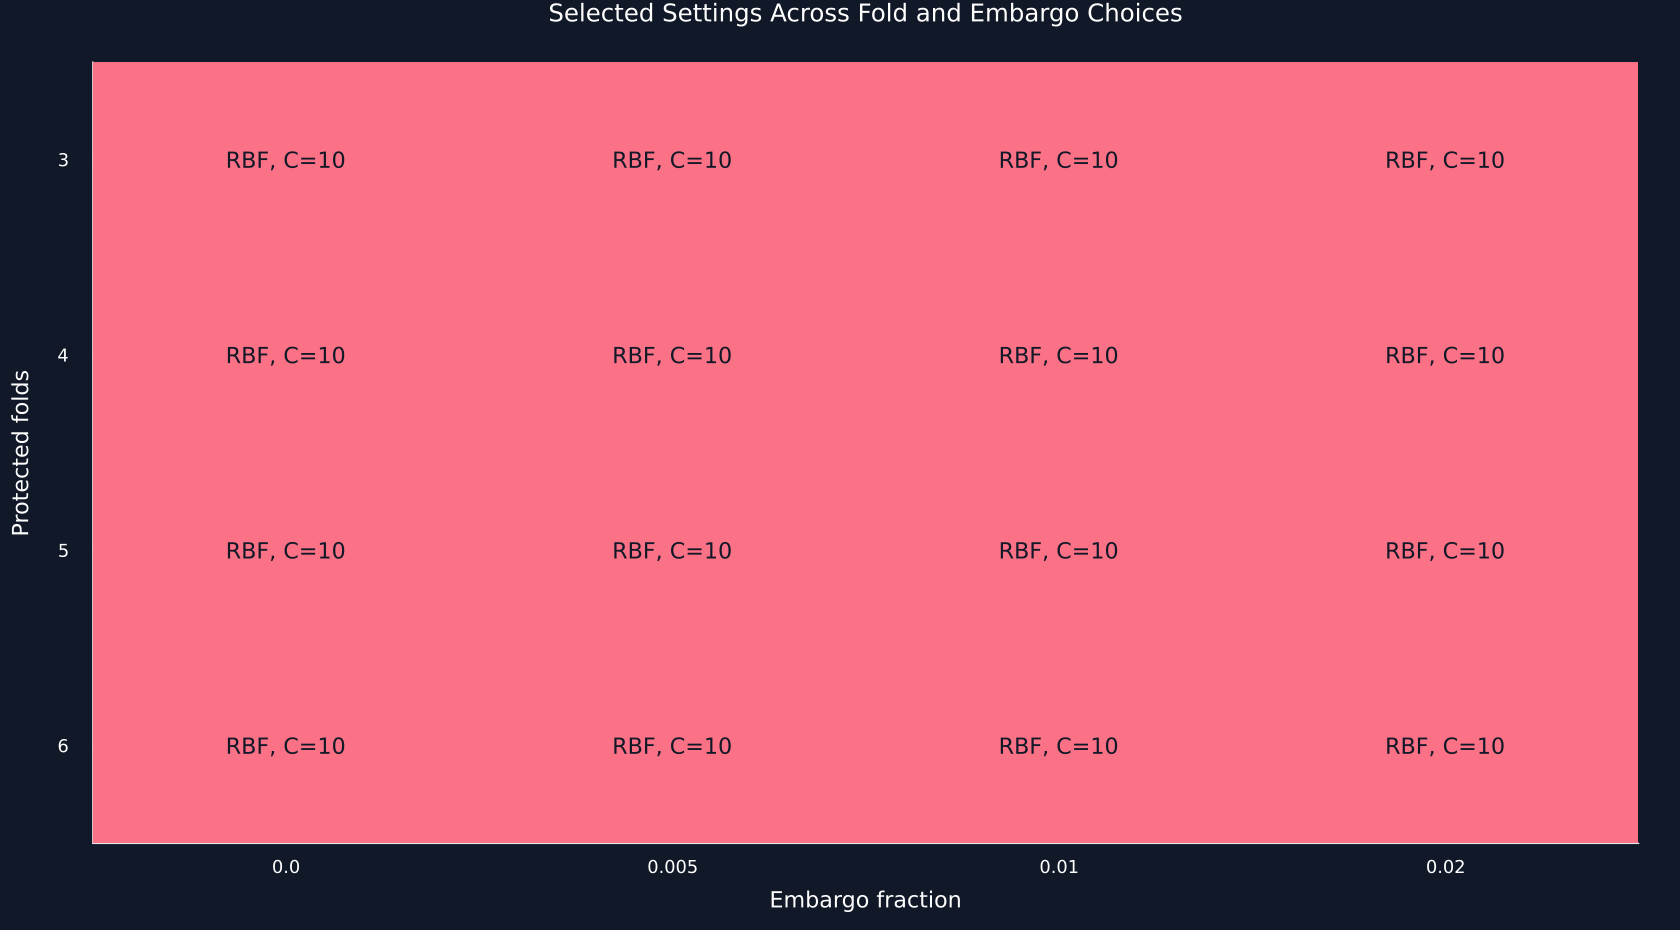

In [3]:
protection_configurations = configurations([1.,10.])
fold_values,embargo_values = [3,4,5,6],[0.,.005,.01,.02]
protection_records = NamedTuple[]
for folds in fold_values, (embargo_index,embargo) in enumerate(embargo_values)
    surface,_ = configuration_surface(protection_configurations;folds,embargo,key="protection_"*string(folds)*"_"*string(embargo_index))
    ordered = sort(surface,["Mean F1","Order"];rev=[true,false])
    best,second = ordered[1,:],ordered[2,:]
    push!(protection_records,(folds=folds,embargo=embargo,kernel=best.Kernel,C=best.C,best=best["Mean F1"],spread=best["F1 spread"],margin=best["Mean F1"]-second["Mean F1"],removed=best["Mean removed observations"]))
end
protection_sensitivity = DataFrame(protection_records)
rename!(protection_sensitivity,["Folds","Embargo fraction","Selected kernel","Selected C","Best mean F1","F1 spread","Score margin","Mean removed observations"])
protection_selection_frequency = selection_frequency(protection_sensitivity,"Selections")
table(protection_sensitivity,"protection_sensitivity","Selected settings across sixteen fold and embargo choices.")
table(protection_selection_frequency,"protection_selection_frequency","Selection frequencies across fold and embargo choices.")
setting_labels = [configuration_name(kernel,penalty) for (kernel,penalty) in protection_configurations]
selection_matrix = zeros(Int,4,4)
for (row,folds) in enumerate(fold_values), (column,embargo) in enumerate(embargo_values)
    selected = only(eachrow(protection_sensitivity[(protection_sensitivity.Folds.==folds).&(protection_sensitivity[!,"Embargo fraction"].==embargo),:]))
    selection_matrix[row,column] = findfirst(==(configuration_name(selected["Selected kernel"],selected["Selected C"])),setting_labels)
end
figure = heatmap(1:4,1:4,selection_matrix;color=cgrad([palette.cyan,palette.amber,palette.green,palette.rose],categorical=true),clims=(.5,4.5),colorbar=false,yflip=true,xticks=(1:4,string.(embargo_values)),yticks=(1:4,string.(fold_values)),title="Selected Settings Across Fold and Embargo Choices",xlabel="Embargo fraction",ylabel="Protected folds",size=(1120,620),grid=false)
for row in 1:4, column in 1:4
    annotate!(figure,column,row,text(setting_labels[selection_matrix[row,column]],10,palette.background,:center))
end
save_figure(figure,paths,"protection_selection_map")


The winning margin in history $m$ is the difference between its best and second-best protected scores:

$$
M_m=\overline s_m^{(1)}-\overline s_m^{(2)}.
$$

Here, $\overline s_m^{(1)}$ is the largest protected mean score in history $m$, $\overline s_m^{(2)}$ is the second largest, and $M_m$ is the score margin. A small margin means that a minor score change could reverse the choice.

## Stability Summary

In [4]:
expanding_probabilities = expanding_selection_frequency[!,"Selection share"]
protection_probabilities = protection_selection_frequency[!,"Selection share"]
expanding_entropy = -sum(expanding_probabilities.*log.(expanding_probabilities))/log(length(stability_configurations))
protection_entropy = -sum(protection_probabilities.*log.(protection_probabilities))/log(length(protection_configurations))
adjacent_changes = count((expanding_history_selections[2:end,"Selected kernel"].!=expanding_history_selections[1:end-1,"Selected kernel"]).|(expanding_history_selections[2:end,"Selected C"].!=expanding_history_selections[1:end-1,"Selected C"]))
stability_summary = DataFrame("Quantity"=>["Expanding histories","Distinct expanding-history selections","Most common expanding selection share","Expanding selection entropy","Adjacent selection changes","Mean expanding score margin","Smallest expanding score margin","Fold and embargo designs","Distinct protection-design selections","Protection-design selection entropy"],"Value"=>[7,nrow(expanding_selection_frequency),maximum(expanding_probabilities),expanding_entropy,adjacent_changes,mean(expanding_history_selections[!,"Score margin"]),minimum(expanding_history_selections[!,"Score margin"]),16,nrow(protection_selection_frequency),protection_entropy])
table(stability_summary,"stability_summary","Selection-stability summary for the public experiment.")


Row,Quantity,Value
,String,Float64
1,Expanding histories,7.0
2,Distinct expanding-history selections,3.0
3,Most common expanding selection share,0.428571
4,Expanding selection entropy,0.518886
5,Adjacent selection changes,4.0
6,Mean expanding score margin,0.0331002
7,Smallest expanding score margin,0.0
8,Fold and embargo designs,16.0
9,Distinct protection-design selections,1.0


## Tests

In [5]:
@assert length(history_sizes)==7
@assert last(history_sizes)==count_observations
@assert size(expanding_history_selections)==(7,8)
@assert size(expanding_history_surface)==(56,7)
@assert all(value->0<=value<=1,expanding_history_selections[!,"Best mean F1"])
@assert all(value->0<=value<=1,expanding_history_selections[!,"Second mean F1"])
@assert all(>=(0),expanding_history_selections[!,"Score margin"])
@assert sum(expanding_selection_frequency.Selections)==7
@assert sum(expanding_probabilities)≈1
@assert 0<=expanding_entropy<=1
@assert size(score_pivot)==(8,7)
@assert size(protection_sensitivity)==(16,8)
@assert all(value->0<=value<=1,protection_sensitivity[!,"Best mean F1"])
@assert all(>=(0),protection_sensitivity[!,"Score margin"])
@assert all(>=(0),protection_sensitivity[!,"Mean removed observations"])
@assert sum(protection_selection_frequency.Selections)==16
@assert sum(protection_probabilities)≈1
@assert 0<=protection_entropy<=1
@assert size(selection_matrix)==(4,4)
@assert all(value->value in 1:4,selection_matrix)
@assert 0<=adjacent_changes<=6
@assert size(stability_summary)==(10,2)
@assert all(row.converged for row in fit_records)
@assert isfile(joinpath(paths.figures,"expanding_history_stability.pdf"))
@assert isfile(joinpath(paths.figures,"expanding_score_surface.pdf"))
@assert isfile(joinpath(paths.figures,"protection_selection_map.pdf"))
@assert isfile(joinpath(paths.tables,"expanding_history_selections.tex"))
@assert isfile(joinpath(paths.tables,"expanding_history_surface.tex"))
@assert isfile(joinpath(paths.tables,"expanding_selection_frequency.tex"))
@assert isfile(joinpath(paths.tables,"protection_sensitivity.tex"))
@assert isfile(joinpath(paths.tables,"protection_selection_frequency.tex"))
@assert isfile(joinpath(paths.tables,"stability_summary.tex"))
